# PNGB MaVaN plots

Simple notebook for the PNGB potential

$
V(\phi)=V_0\left[1+\cos\left(\frac{\phi}{f}\right)\right],
\qquad
m_\nu(\phi)=m_{\nu,0}e^{\beta(\phi-\phi_0)}.
$

The four CLASS runs are explicit (`model1` to `model4`) so that each
case can be changed directly.  The defaults keep the PNGB potential
fixed and vary only \(\beta\).


In [11]:
from pathlib import Path

import classy
from classy import Class
import matplotlib.pyplot as plt
import numpy as np

print("classy:", classy.__file__)

# Numerical and plotting controls
K_H_MPC = np.geomspace(1.0e-4, 1.0, 600)
Z_PK = 0.0
L_MAX = 2500
Z_PHYSICAL_EOS_MAX = 10.0
Z_APPARENT_MAX = 3.0  # w_app may have a pole at higher redshift

MNU0_EV = 0.06
T_NCDM = 0.71611
T_CMB_UK = 2.7255e6
USE_NONLINEAR_PK = True

SAVE_FIGURES = True
FIGURE_DIR = Path("plots_pngb_mavan")
if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)


classy: /home/usuario/anaconda3/lib/python3.12/site-packages/classy/__init__.py


## CLASS parameters

For this implementation,

```text
scf_parameters = f, log10(V0), phi_ini, phi_prime_ini
```

`Omega_scf = -1` and `scf_tuning_index = 1` shoot the second entry to
the required present scalar density.  The default initial point obeys
$0<\phi_{\rm ini}<\pi f$, so the PNGB slope drives $\phi$ toward
larger values.  With $\beta>0$, this is the branch relevant for a
lighter neutrino mass in the past and apparent phantom behavior.


In [2]:
common_params = {
    "H0": 70.0,
    "omega_b": 0.02238280,
    "omega_cdm": 0.1201075,
    "A_s": 2.100549e-9,
    "n_s": 0.9660499,

    # One massive species with m_nu,0 = 0.06 eV.
    "N_ur": 2.0308,
    "N_ncdm": 1,
    "m_ncdm": MNU0_EV,
    "T_ncdm": T_NCDM,
    "deg_ncdm": 1,

    "Omega_fld": 0.0,
    "Omega_Lambda": 0.0,
    "Omega_scf": -1,
    "scf_tuning_index": 1,
    "attractor_ic_scf": "no",

    "output": "mPk,tCl,pCl,lCl",
    "lensing": "yes",
    "l_max_scalars": L_MAX,
    "P_k_max_h/Mpc": 1.05 * K_H_MPC[-1],
    "non_linear": "halofit" if USE_NONLINEAR_PK else "none",
}

# scf_parameters = f, shooting guess for log10(V0), phi_ini, phi'_ini
params1 = {
    **common_params,
    "beta_ncdm": 0.0,
    "scf_parameters": "0.50, -7.00, 0.40, 0.0",
}
params2 = {
    **common_params,
    "beta_ncdm": 1.0,
    "scf_parameters": "0.50, -7.00, 0.40, 0.0",
}
params3 = {
    **common_params,
    "beta_ncdm": 3.0,
    "scf_parameters": "0.50, -7.00, 0.40, 0.0",
}
params4 = {
    **common_params,
    "beta_ncdm": 5.0,
    "scf_parameters": "0.50, -7.00, 0.40, 0.0",
}

labels = (
    r"$\beta=0$",
    r"$\beta=1.0$",
    r"$\beta=3$",
    r"$\beta=5.0$",
)
colors = ("black", "tab:blue", "tab:green", "tab:red")
linestyles = ("-", "--", ":", "-.")


## Run the four models


In [3]:
model1 = Class()
model1.set(params1)
model1.compute()

model2 = Class()
model2.set(params2)
model2.compute()

model3 = Class()
model3.set(params3)
model3.compute()

model4 = Class()
model4.set(params4)
model4.compute()

models = (model1, model2, model3, model4)
parameters = (params1, params2, params3, params4)
print("All four CLASS models completed.")


All four CLASS models completed.


## Background quantities

The complete interacting scalar equation of state is

$
w_{\phi,\mathrm{eff}}
=w_\phi+
\frac{\beta}{3}\frac{d\phi}{d\ln a}
\frac{\rho_\nu-3p_\nu}{\rho_\phi},
$

which remains valid through the relativistic-to-nonrelativistic
transition.  The exact apparent fluid is

$
w_{\mathrm{app}}=
\frac{p_\phi+p_\nu-p_{\nu,\mathrm{const}}}
{\rho_\phi+\rho_\nu-\rho_{\nu,\mathrm{const}}}.
$


In [4]:
def divide(numerator, denominator):
    '''Safe element-wise division.'''
    numerator, denominator = np.broadcast_arrays(numerator, denominator)
    result = np.full(numerator.shape, np.nan, dtype=float)
    valid = np.isfinite(numerator) & np.isfinite(denominator)
    valid &= denominator != 0.0
    np.divide(numerator, denominator, out=result, where=valid)
    return result


def pngb_f(params):
    return float(params["scf_parameters"].split(",")[0])


def background_data(model, params):
    bg = model.get_background()

    z = np.asarray(bg["z"], dtype=float)
    a = 1.0 / (1.0 + z)
    H = np.asarray(bg["H [1/Mpc]"], dtype=float)
    phi = np.asarray(bg["phi_scf"], dtype=float)
    phi_prime = np.asarray(bg["phi'_scf"], dtype=float)
    rho_phi = np.asarray(bg["(.)rho_scf"], dtype=float)
    p_phi = np.asarray(bg["(.)p_scf"], dtype=float)
    rho_nu = np.asarray(bg["(.)rho_ncdm[0]"], dtype=float)
    p_nu = np.asarray(bg["(.)p_ncdm[0]"], dtype=float)

    beta = params["beta_ncdm"]
    f_pngb = pngb_f(params)
    phi0 = phi[np.argmin(np.abs(z))]
    dphi_dln_a = divide(phi_prime, a * H)
    w_phi = divide(p_phi, rho_phi)

    # Exact interaction trace: no nonrelativistic approximation.
    w_phi_eff = w_phi + divide(
        beta * dphi_dln_a * (rho_nu - 3.0 * p_nu),
        3.0 * rho_phi,
    )

    return {
        "z": z,
        "a": a,
        "phi": phi,
        "phi_prime": phi_prime,
        "phi_over_f": phi / f_pngb,
        "phi0": phi0,
        "rho_phi": rho_phi,
        "p_phi": p_phi,
        "rho_nu": rho_nu,
        "p_nu": p_nu,
        "w_phi": w_phi,
        "w_phi_eff": w_phi_eff,
        "mnu": MNU0_EV * np.exp(
            np.clip(beta * (phi - phi0), -700.0, 700.0)
        ),
    }


data1 = background_data(model1, params1)
data2 = background_data(model2, params2)
data3 = background_data(model3, params3)
data4 = background_data(model4, params4)
data = (data1, data2, data3, data4)


In [5]:
def interpolate_positive(z_reference, quantity_reference, z_target):
    '''Interpolate a positive background quantity in ln(1+z).'''
    x = np.log1p(z_reference)
    y = np.asarray(quantity_reference, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y) & (y > 0.0)
    order = np.argsort(x[valid])
    return np.exp(
        np.interp(
            np.log1p(z_target),
            x[valid][order],
            np.log(y[valid][order]),
        )
    )


# The beta=0 run supplies the exact constant-present-mass neutrino fluid.
for result in data:
    rho_nu_const = interpolate_positive(
        data1["z"], data1["rho_nu"], result["z"]
    )
    p_nu_const = interpolate_positive(
        data1["z"], data1["p_nu"], result["z"]
    )

    result["rho_de_app"] = (
        result["rho_phi"] + result["rho_nu"] - rho_nu_const
    )
    result["p_de_app"] = (
        result["p_phi"] + result["p_nu"] - p_nu_const
    )
    result["w_app"] = divide(
        result["p_de_app"], result["rho_de_app"]
    )

# At beta=0, w_app must equal w_phi.
mask0 = np.isfinite(data1["w_app"]) & np.isfinite(data1["w_phi"])
print(
    "max |w_app - w_phi| for beta=0:",
    np.max(np.abs(data1["w_app"][mask0] - data1["w_phi"][mask0])),
)

# Locate any high-redshift pole caused by rho_DE,app crossing zero.
for result, label in zip(data, labels):
    order = np.argsort(result["z"])
    z = result["z"][order]
    rho_app = result["rho_de_app"][order]
    finite = np.isfinite(rho_app[:-1]) & np.isfinite(rho_app[1:])
    crossing = np.flatnonzero(
        finite & (np.signbit(rho_app[:-1]) != np.signbit(rho_app[1:]))
    )
    if crossing.size:
        i = crossing[0]
        x1, x2 = np.log1p(z[i]), np.log1p(z[i + 1])
        x_pole = x1 - rho_app[i] * (x2 - x1) / (rho_app[i + 1] - rho_app[i])
        print(label, "w_app pole near z =", np.expm1(x_pole))


max |w_app - w_phi| for beta=0: 19.0
$\beta=0$ w_app pole near z = 85016.88069790139
$\beta=1.0$ w_app pole near z = 12.54377364641632
$\beta=3$ w_app pole near z = 9.437780349256101
$\beta=5.0$ w_app pole near z = 8.346581494466298


## Spectra


In [6]:
spectra = []
for model in models:
    h = model.h()

    cls = model.lensed_cl(L_MAX)
    ell = np.asarray(cls["ell"], dtype=int)
    cl_tt = np.asarray(cls["tt"], dtype=float)
    dl_tt = ell * (ell + 1.0) * cl_tt * T_CMB_UK**2 / (2.0 * np.pi)

    pk = np.asarray(
        model.get_pk_all(
            K_H_MPC * h,
            Z_PK,
            nonlinear=USE_NONLINEAR_PK,
        ),
        dtype=float,
    ).squeeze() * h**3

    spectra.append({"ell": ell, "dl_tt": dl_tt, "pk": pk})


## Scalar-field position on the PNGB potential


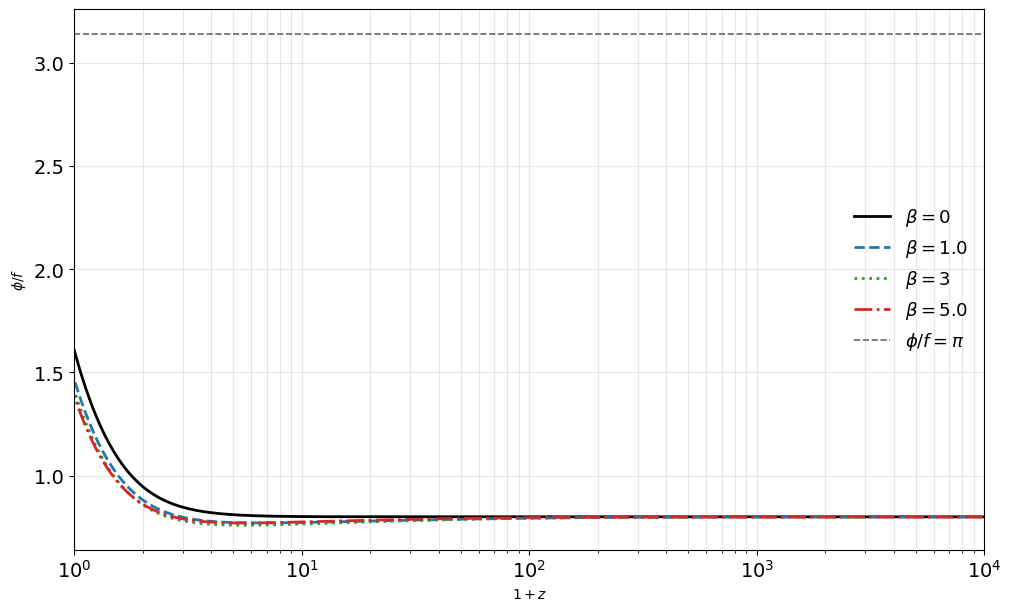

In [7]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for result, label, color, ls in zip(data, labels, colors, linestyles):
    ax.semilogx(
        1.0 + result["z"], result["phi_over_f"],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

ax.axhline(np.pi, color="0.4", linestyle="--", linewidth=1.2,
           label=r"$\phi/f=\pi$")
ax.set(
    xlabel=r"$1+z$",
    ylabel=r"$\phi/f$",
    xlim=(1.0, 1.0e4),
)
ax.tick_params(axis="both", which="major", labelsize=14)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=13, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "phi_over_f_vs_z.pdf", bbox_inches="tight")
plt.show()


## Effective neutrino mass


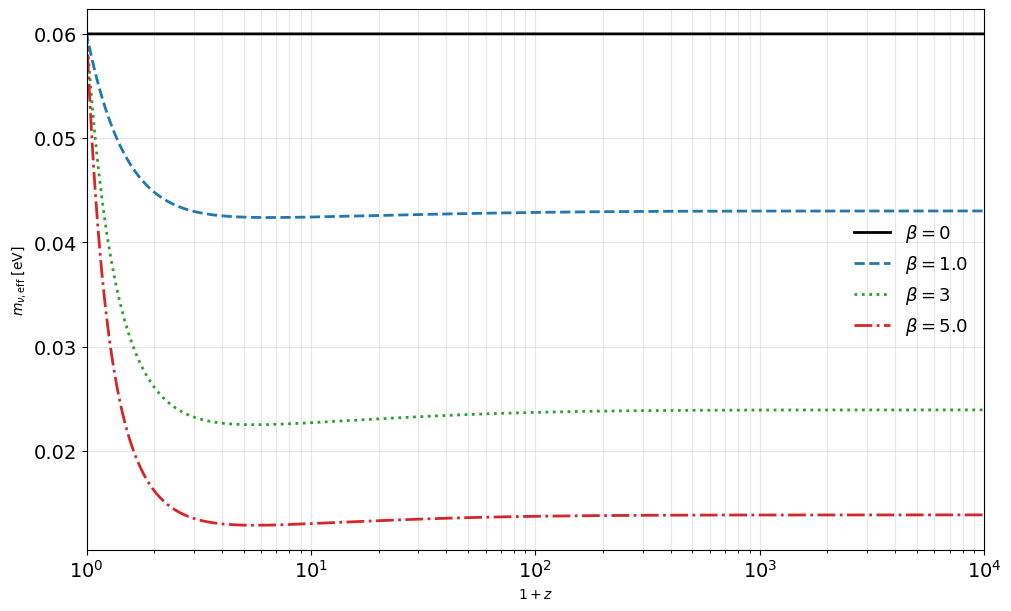

In [8]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for result, label, color, ls in zip(data, labels, colors, linestyles):
    ax.semilogx(
        1.0 + result["z"], result["mnu"],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

ax.set(
    xlabel=r"$1+z$",
    ylabel=r"$m_{\nu,\mathrm{eff}}\;[\mathrm{eV}]$",
    xlim=(1.0, 1.0e4),
)
ax.tick_params(axis="both", which="major", labelsize=14)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=13, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "m_eff_vs_z.pdf", bbox_inches="tight")
plt.show()


## CMB temperature spectrum \(D_\ell^{TT}\)


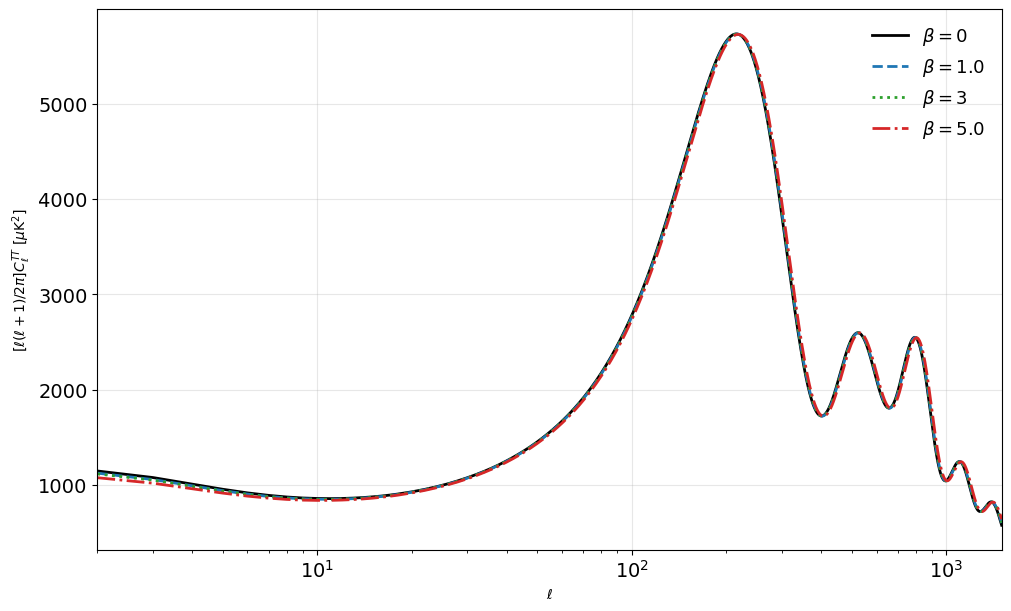

In [9]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for spectrum, label, color, ls in zip(
    spectra, labels, colors, linestyles
):
    mask = (spectrum["ell"] >= 2) & (spectrum["ell"] <= 1500)
    ax.semilogx(
        spectrum["ell"][mask], spectrum["dl_tt"][mask],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

ax.set(
    xlabel=r"$\ell$",
    ylabel=r"$[\ell(\ell+1)/2\pi]C_\ell^{TT}\;[\mu\mathrm{K}^2]$",
    xlim=(2, 1500),
)
ax.tick_params(axis="both", which="major", labelsize=14)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=13, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "cltt_pngb.pdf", bbox_inches="tight")
plt.show()


## Matter power spectrum


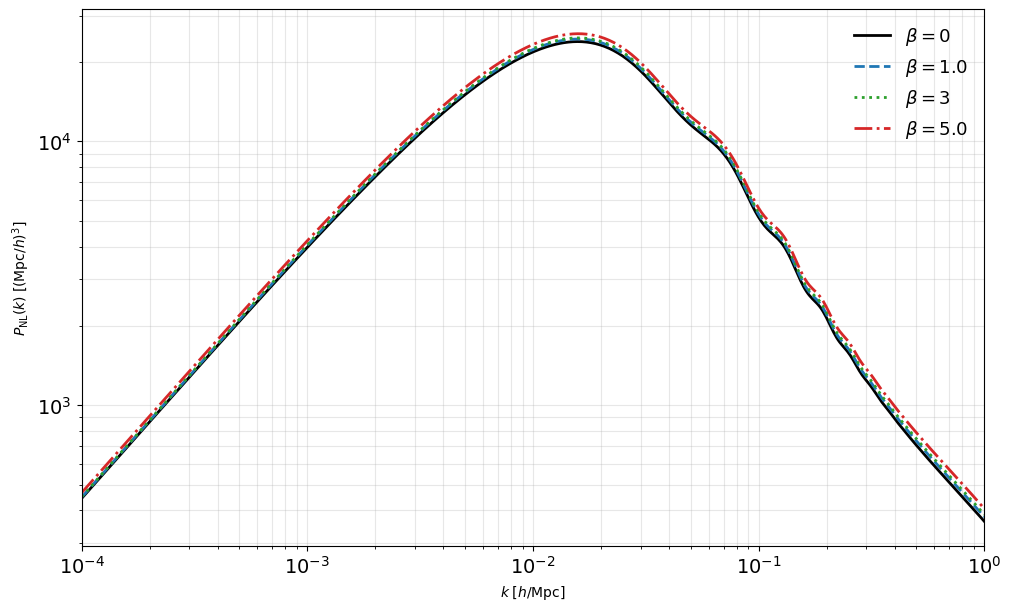

In [10]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for spectrum, label, color, ls in zip(
    spectra, labels, colors, linestyles
):
    ax.loglog(
        K_H_MPC, spectrum["pk"],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

pk_label = r"$P_{\rm NL}(k)\;[(\mathrm{Mpc}/h)^3]$" if USE_NONLINEAR_PK \
    else r"$P_{\rm lin}(k)\;[(\mathrm{Mpc}/h)^3]$"
ax.set(
    xlabel=r"$k\;[h/\mathrm{Mpc}]$",
    ylabel=pk_label,
    xlim=(K_H_MPC[0], K_H_MPC[-1]),
)
ax.tick_params(axis="both", which="major", labelsize=14)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=13, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "pk_pngb.pdf", bbox_inches="tight")
plt.show()


## Intrinsic, interacting-effective, and apparent equations of state


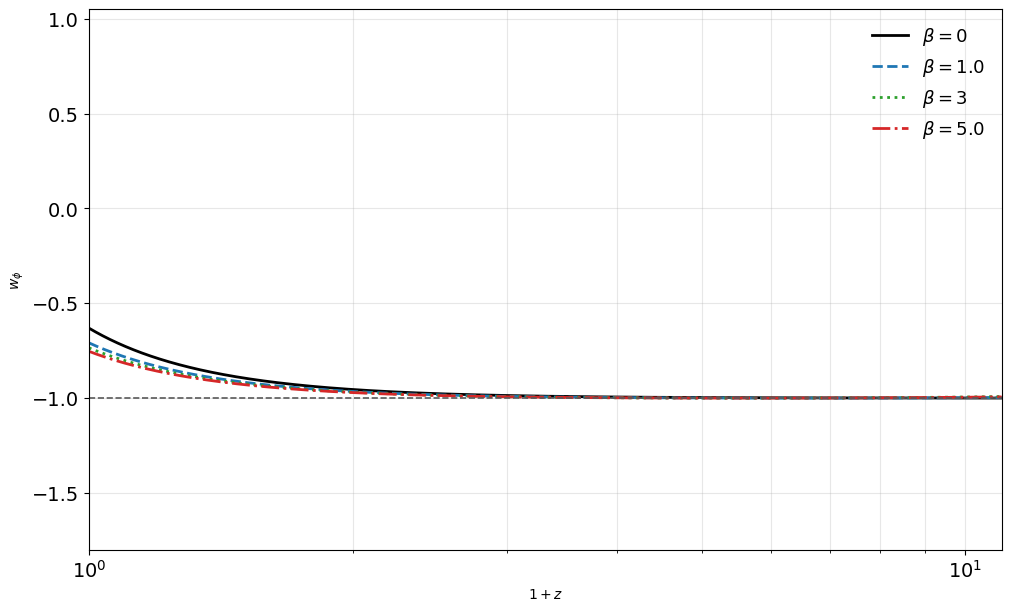

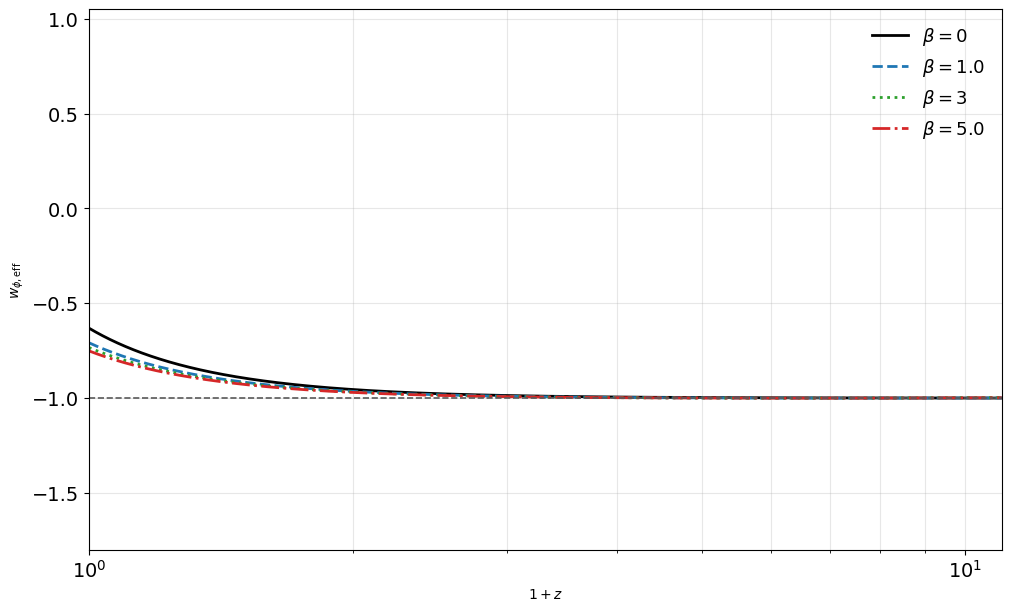

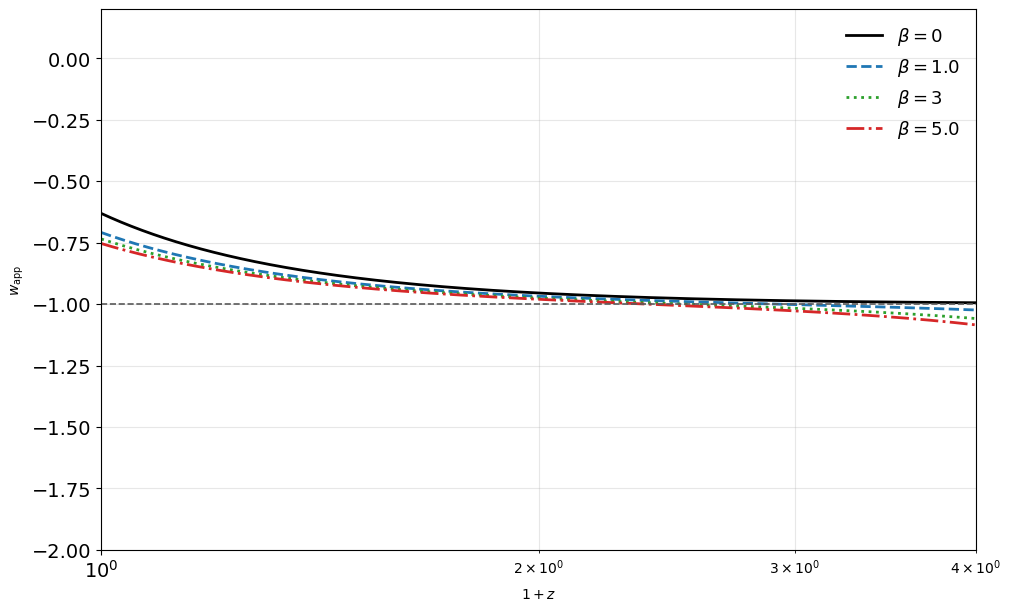

In [11]:
def plot_eos(key, ylabel, filename, zmax, ylim):
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

    for result, label, color, ls in zip(
        data, labels, colors, linestyles
    ):
        mask = (result["z"] >= 0.0) & (result["z"] <= zmax)
        order = np.argsort(result["z"][mask])
        z = result["z"][mask][order]
        eos = result[key][mask][order]

        ax.plot(
            1.0 + z, eos,
            color=color, linestyle=ls, linewidth=2, label=label,
        )

    ax.set_xscale("log")
    ax.set(
        xlabel=r"$1+z$",
        ylabel=ylabel,
        xlim=(1.0, 1.0 + zmax),
        ylim=ylim,
    )
    ax.axhline(-1.0, color="0.35", linestyle="--", linewidth=1.2)
    ax.tick_params(axis="both", which="major", labelsize=14)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=13, frameon=False)

    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()


plot_eos(
    "w_phi", r"$w_\phi$", "w_phi_eos.pdf",
    Z_PHYSICAL_EOS_MAX, (-1.8, 1.05),
)

plot_eos(
    "w_phi_eff", r"$w_{\phi,\mathrm{eff}}$", "w_phi_eff_eos.pdf",
    Z_PHYSICAL_EOS_MAX, (-1.8, 1.05),
)

# At higher redshift rho_DE,app can cross zero, giving a pole in w_app
# even though the physical background remains regular.
plot_eos(
    "w_app", r"$w_{\mathrm{app}}$", "w_app_eos.pdf",
    Z_APPARENT_MAX, (-2.0, 0.2),
)
